# Deep MLP encoder on frozen features — capacity or information?

Two earlier results sit in tension.

- `mlp` — the R-GCN replaced by a message-free `Linear`, on the library's **frozen** Xavier-random
  node features — collapses to **0.5285** indication AUPRC against the R-GCN's 0.8318, barely above the
  0.500 chance floor.
- `emb_mlp` — the *same* message-free encoder, but with the node features made **learnable** (a
  12,931,200-parameter table) — reaches **0.8181**, statistically indistinguishable from full TxGNN.

So message passing is not what the R-GCN is buying. But the `mlp` arm had only **20,200** parameters,
2.0% of the encoder it replaced, so its collapse has never been separated into two candidate causes:

1. **Information.** A frozen random vector carries nothing about the node but its identity, and a small
   MLP cannot decode identity into anything useful.
2. **Capacity.** The 20,200-parameter encoder was simply too small, whatever its input.

This grid separates them. Every arm keeps the KG intact, keeps the features **frozen**, and never adds
a learnable embedding table. Only the encoder's size and shape change.

| arm | message passing | shape | encoder params | status |
|---|---|---|---|---|
| `rgcn` | yes | one `Linear(100,100)` per edge type | 1,010,000 | imported |
| `light_gnn` | yes | one shared `Linear(100,100)` | 20,200 | imported |
| `mlp` | **no** | one `Linear(100,100)` | 20,200 | imported |
| **`light_gnn_wide`** | yes | shared, widened internally | ~1,010,024 | **new** |
| **`mlp_wide`** | **no** | widened internally | ~1,010,024 | **new** |
| **`deep_mlp_rz_2`** | **no** | 2 residual blocks | 20,202 | **new** |
| **`deep_mlp_rz_8`** | **no** | 8 residual blocks | 80,808 | **new** |
| **`deep_mlp_rz_32`** | **no** | 32 residual blocks | 323,232 | **new** |
| **`deep_mlp_rz_64`** | **no** | 64 residual blocks | 646,464 | **new** |
| **`deep_mlp_rz_100`** | **no** | 100 residual blocks | **1,010,100** | **new** |

`deep_mlp_rz_100` is parameter-matched to the R-GCN to within 0.01%: 100 blocks ×
(100·100 + 100 + 1) = 1,010,100 against 1,010,000, with zero message passing.

### Why depth is the interesting axis

The frozen features are not noise in the useless sense — each node's vector is a unique fingerprint. A
sufficiently flexible function of that fingerprint *is* a lookup table, so in the limit a deep enough
MLP can learn whatever `emb_mlp`'s embedding table learned. `deep_mlp_rz_*` therefore interpolates between
`mlp` (20,200) and `emb_mlp` (12.9M learnable, matches TxGNN) **without ever making the
features learnable**. Two outcomes, both informative:

- **It climbs toward 0.82.** Then the frozen features were never the obstacle; the shallow encoder's
  lack of capacity to decode them was, and `emb_mlp`'s advantage is optimisation convenience rather
  than extra information.
- **It stays near 0.53.** Then no amount of per-node function approximation substitutes for
  per-node *free parameters*, and the frozen-feature confound is about the gradient path, not capacity.

`mlp_wide` is the control that makes this a depth result rather than a size result: the same
parameter budget as `deep_mlp_rz_100`, spent on one wide layer instead of a hundred narrow ones.

### Architecture notes

**Widening is internal.** `n_inp = n_hid = n_out = 100` in every arm, so `w_rels`, `DistMultPredictor`,
the `rarity` gate, pre-training and fine-tuning are bit-for-bit the library's — only the encoder's
internals change. The wide arms use `Linear(100, H) → LeakyReLU → Linear(H, 100)` with `H = 2512`;
the deep arms stack residual blocks at width 100. This also keeps per-edge activation memory identical
to the narrow arms, which matters: widening `n_hid` to 955 instead would make `light_gnn`'s messages
955-dimensional over 6.73M edges and need ~26 GB.

**The residual block** is `h ← h + g·W(LeakyReLU(LayerNorm(h)))`, pre-norm, with
`elementwise_affine=False` so the LayerNorm contributes **no** parameters and the count stays exactly
`depth × 10,101`. A hundred plain stacked `Linear` layers would not train; this is the minimum
structure that does. It is a deliberate departure from the 2-layer `mlp` arm's shape, which is why
`deep_mlp_rz_2` is included — the depth curve is then internally consistent, and `mlp` sits beside it
as the original.

**Gradient checkpointing** is on for the deeper arms (`CKPT_MIN_DEPTH`). Each block is a deterministic,
side-effect-free function, so recomputing it in the backward pass is exact; without it, 100 blocks over
129,312 nodes retains roughly 20 GB.

### The residual blocks carry a learnable gain

Each block is `h ← h + g·W(LeakyReLU(LayerNorm(h)))`, pre-norm, with `g` a learnable scalar
initialised to `1/√depth`.

Without the gain the stack is not trainable at depth: an unscaled residual adds a roughly
unit-variance term per block, so `‖h‖` grows like `√depth`, and because DistMult scores
`Σ hᵤ·w_r·hᵥ` — a product of two embeddings — the logits grow with depth until the sigmoid
saturates and its gradient vanishes. Initialising `g` at `1/√depth` cancels that growth
exactly, so the embedding scale is depth-independent; a zero init would also do that but
stalls `W` until `g` moves off zero, whereas `1/√depth` leaves every gradient non-zero from
the first step. `g` is learnable, so a block that earns a louder voice gets one.

Cost: one parameter per block, so a block is `width² + width + 1` and depth 100 is 1,010,100
against the R-GCN's 1,010,000 — a 0.01% overshoot. §9.1a checks the measured `embedding_rms`
is flat across depth rather than assuming it.


---
## 1 · Environment

In [1]:
import os, sys, json, time, gc, random, shutil, inspect, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')


def _find_repo_root(start=None):
    p = Path(start or os.getcwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / 'pyg_implementation' / 'txgnn').is_dir():
            return cand
    raise RuntimeError('Could not find pyg_implementation/txgnn above ' + str(p))


REPO_ROOT = _find_repo_root()
PYG_ROOT  = REPO_ROOT / 'pyg_implementation'
sys.path.insert(0, str(PYG_ROOT))   # PyG port FIRST, so `import txgnn` never hits dgl_implementation/

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint
from torch_scatter import scatter

import txgnn
from txgnn import TxData, TxGNN
from txgnn.model import HeteroRGCN, HeteroRGCNLayer
from txgnn.utils import evaluate_fb, create_pyg_graph, get_n_params

assert 'pyg_implementation' in txgnn.__file__, (
    'Wrong txgnn package on sys.path (%s). Restart the kernel.' % txgnn.__file__)

_MI_PARAMS = set(inspect.signature(TxGNN.model_initialize).parameters)
assert 'use_decision_network' not in _MI_PARAMS, (
    'model_initialize accepts use_decision_network again - revisit MODEL_CFG before trusting this grid.')

DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'


def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


print('repo  :', REPO_ROOT)
print('txgnn :', txgnn.__file__)
print('torch :', torch.__version__, '| device:', DEVICE,
      '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else platform.processor())

repo  : /home/dsls/Desktop/projects/BardiaSabbagh/txgnn-refactor
txgnn : /home/dsls/Desktop/projects/BardiaSabbagh/txgnn-refactor/pyg_implementation/txgnn/__init__.py
torch : 2.6.0+cu118 | device: cuda:0 | NVIDIA GeForce RTX 4060 Ti


---
## 2 · Configuration

Seeds, split and schedule match `ablation_encoder_swap`, so `rgcn`, `light_gnn` and `mlp` import cleanly and every delta is paired per seed.

In [2]:
SPLIT   = 'complex_disease'
SEEDS   = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 31, 41, 42, 63, 70, 77, 86, 89, 95, 98]
PROFILE = 'full'

MODEL_CFG = dict(
    n_hid       = 100,          # held at 100 in every arm: widening is internal to the encoder
    n_inp       = 100,
    n_out       = 100,
    proto       = True,
    proto_num   = 3,
    attention   = False,
    sim_measure = 'all_nodes_profile',
    agg_measure = 'rarity',
)

PRETRAIN_CFG = dict(n_epoch=1,    learning_rate=1e-3, batch_size=1024, train_print_per_n=500)
FINETUNE_CFG = dict(n_epoch=1000, learning_rate=5e-4, train_print_per_n=100, valid_per_n=20)

TARGET_ENCODER_PARAMS = 1_010_000   # the R-GCN encoder, 50 edge types at width 100

# published reference points, for the summary table only (different model_config, so not imported)
EMB_MLP_INDICATION = 0.8181   # grid 7: message-free encoder + 12.9M learnable embedding table

DD_REL     = ['contraindication', 'indication', 'off-label use']
DD_REV_REL = ['rev_' + r for r in DD_REL]
DD_ETYPES  = [('drug', r, 'disease') for r in DD_REL] + [('disease', r, 'drug') for r in DD_REV_REL]

SIG_ETYPES_DEFAULT = ['disease_disease', 'rev_disease_protein']   # must be present in every arm

DATA_FOLDER = REPO_ROOT / 'data'
ABL_ROOT    = REPO_ROOT / 'results' / 'ablation_deep_mlp'
SWAP_ROOT   = REPO_ROOT / 'results' / 'ablation_encoder_swap'   # read-only
ABL_ROOT.mkdir(parents=True, exist_ok=True)

REF_ARM = 'rgcn'

# --- switches ------------------------------------------------------------------------------------
RUN_GRID          = True
IMPORT_REFS       = True
PROBE_ENCODER     = True    # measure graph_sensitivity after every run
CKPT_MIN_DEPTH    = 16      # checkpoint residual blocks at or above this depth
STOP_AFTER_N_RUNS = None

print('split  :', SPLIT)
print('seeds  : %d -> %s' % (len(SEEDS), SEEDS))
print('results:', ABL_ROOT.relative_to(REPO_ROOT))

split  : complex_disease
seeds  : 20 -> [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 31, 41, 42, 63, 70, 77, 86, 89, 95, 98]
results: results/ablation_deep_mlp


---
## 3 · The encoders

Three new layer types. All of them keep the `in_size → out_size` interface the library expects, so
nothing downstream of the encoder is touched.

In [3]:
class MLPLayer(nn.Module):
    """No message passing: h[nt] = W x[nt]. The original narrow arm, kept so this grid can
    train `mlp` itself if the import from ablation_encoder_swap is ever unavailable."""

    def __init__(self, in_size, out_size):
        super().__init__()
        self.weight = nn.Linear(in_size, out_size)
        self.in_size, self.out_size = in_size, out_size

    def forward(self, G, feat_dict):
        return {nt: self.weight(feat_dict[nt]) for nt in G.node_types}


class SharedRelationLayer(nn.Module):
    """HeteroRGCNLayer's aggregation with ONE weight shared by all relations (narrow light_gnn)."""

    def __init__(self, in_size, out_size):
        super().__init__()
        self.weight = nn.Linear(in_size, out_size)
        self.in_size, self.out_size = in_size, out_size

    def forward(self, G, feat_dict):
        Wh = {nt: self.weight(feat_dict[nt]) for nt in G.node_types}
        out = {nt: None for nt in G.node_types}

        for srctype, etype, dsttype in G.edge_types:
            ei = G[(srctype, etype, dsttype)].edge_index
            if ei.shape[1] == 0:
                continue
            msg = Wh[srctype][ei[0]]
            agg = scatter(msg, ei[1], dim=0, reduce='mean', dim_size=G[dsttype].num_nodes)
            out[dsttype] = agg if out[dsttype] is None else out[dsttype] + agg

        device = next(iter(feat_dict.values())).device
        for nt in G.node_types:
            if out[nt] is None:
                out[nt] = torch.zeros(G[nt].num_nodes, self.out_size, device=device)
        return out


class WideMLPLayer(nn.Module):
    '''No message passing, widened internally: h[nt] = W2(act(W1 x[nt])). Interface stays in->out.'''

    def __init__(self, in_size, out_size, hidden):
        super().__init__()
        self.fc1 = nn.Linear(in_size, hidden)
        self.fc2 = nn.Linear(hidden, out_size)
        self.in_size, self.out_size, self.hidden = in_size, out_size, hidden

    def transform(self, x):
        return self.fc2(F.leaky_relu(self.fc1(x)))

    def forward(self, G, feat_dict):
        return {nt: self.transform(feat_dict[nt]) for nt in G.node_types}


class WideSharedRelationLayer(WideMLPLayer):
    '''SharedRelationLayer's aggregation, with the shared transform widened internally.

    The message stays out_size-wide, so per-edge activation memory is unchanged.'''

    def forward(self, G, feat_dict):
        Wh = {nt: self.transform(feat_dict[nt]) for nt in G.node_types}
        out = {nt: None for nt in G.node_types}

        for srctype, etype, dsttype in G.edge_types:
            ei = G[(srctype, etype, dsttype)].edge_index
            if ei.shape[1] == 0:
                continue
            msg = Wh[srctype][ei[0]]
            # scatter mean per etype, then sum across etypes - identical to HeteroRGCNLayer
            agg = scatter(msg, ei[1], dim=0, reduce='mean', dim_size=G[dsttype].num_nodes)
            out[dsttype] = agg if out[dsttype] is None else out[dsttype] + agg

        device = next(iter(feat_dict.values())).device
        for nt in G.node_types:
            if out[nt] is None:
                out[nt] = torch.zeros(G[nt].num_nodes, self.out_size, device=device)
        return out


class ResidualBlock(nn.Module):
    '''h + g * W(act(LN(h))), pre-norm, with a learnable scalar gain.

    The gain is why this trains at depth. An unscaled residual stream adds a roughly
    unit-variance term per block, so Var[h] grows about linearly in depth and ||h|| grows
    like sqrt(depth). The decoder then scores sum(h_u * w_r * h_v), which scales with
    ||h_u||*||h_v||, so the logits would grow with depth until the sigmoid saturates and
    its gradient vanishes. Initialising g at 1/sqrt(depth) cancels that growth exactly,
    making the output scale depth-independent, while leaving every gradient non-zero at
    step 0 (unlike a zero init, which stalls W until g has moved off zero). g is learnable,
    so a block that earns a louder voice during training gets one.

    LayerNorm is affine-free, so the block costs exactly width*width + width + 1 params.
    `embedding_rms` is recorded per run to confirm the scale really is flat in depth.'''

    def __init__(self, width, scale_init):
        super().__init__()
        self.norm = nn.LayerNorm(width, elementwise_affine=False)
        self.fc = nn.Linear(width, width)
        self.scale_init = float(scale_init)
        self.gain = nn.Parameter(torch.full((1,), float(scale_init)))

    def forward(self, h):
        return h + self.gain * self.fc(F.leaky_relu(self.norm(h)))


class DeepMLPLayer(nn.Module):
    '''No message passing, deep: a stack of residual blocks applied per node, independently.'''

    def __init__(self, in_size, out_size, n_blocks, scale_init, use_checkpoint=False):
        super().__init__()
        assert in_size == out_size, \
            'DeepMLPLayer is purely residual and needs in_size == out_size (%d vs %d)' % (in_size, out_size)
        self.blocks = nn.ModuleList(
            [ResidualBlock(in_size, scale_init=scale_init) for _ in range(n_blocks)])
        self.scale_init = scale_init
        self.in_size, self.out_size, self.n_blocks = in_size, out_size, n_blocks
        self.use_checkpoint = use_checkpoint

    def transform(self, x):
        h = x
        for b in self.blocks:
            if self.use_checkpoint and self.training:
                # exact: each block is deterministic and side-effect free
                h = checkpoint(b, h, use_reentrant=False)
            else:
                h = b(h)
        return h

    def forward(self, G, feat_dict):
        return {nt: self.transform(feat_dict[nt]) for nt in G.node_types}


def wide_params(hidden, n_inp=100, n_hid=100, n_out=100):
    '''Encoder params for the two widened layers.'''
    return ((n_inp * hidden + hidden) + (hidden * n_hid + n_hid)
            + (n_hid * hidden + hidden) + (hidden * n_out + n_out))


def matched_hidden(target=TARGET_ENCODER_PARAMS, hi=8192):
    best = None
    for h in range(8, hi + 1):
        p = wide_params(h)
        if best is None or abs(p - target) < abs(best[1] - target):
            best = (h, p)
    return best


def deep_params(depth, width=100):
    '''Encoder params for `depth` residual blocks: each is width*width + width + 1.'''
    return depth * (width * width + width + 1)


def residual_scale(depth):
    '''Gain init that makes the residual stream's scale independent of depth.'''
    return depth ** -0.5


WIDE_HIDDEN, WIDE_PARAMS = matched_hidden()

print('wide arms : hidden = %d -> %s encoder params (%+.3f%% of target)'
      % (WIDE_HIDDEN, format(WIDE_PARAMS, ','),
         100.0 * (WIDE_PARAMS - TARGET_ENCODER_PARAMS) / TARGET_ENCODER_PARAMS))
for _d in (2, 8, 32, 64, 100):
    print('deep arms : depth %3d -> %9s encoder params (%5.1f%% of rgcn, gain init %.4f)'
          % (_d, format(deep_params(_d), ','),
             100.0 * deep_params(_d) / TARGET_ENCODER_PARAMS, residual_scale(_d)))

wide arms : hidden = 2512 -> 1,010,024 encoder params (+0.002% of target)
deep arms : depth   2 ->    20,202 encoder params (  2.0% of rgcn, gain init 0.7071)
deep arms : depth   8 ->    80,808 encoder params (  8.0% of rgcn, gain init 0.3536)
deep arms : depth  32 ->   323,232 encoder params ( 32.0% of rgcn, gain init 0.1768)
deep arms : depth  64 ->   646,464 encoder params ( 64.0% of rgcn, gain init 0.1250)
deep arms : depth 100 -> 1,010,100 encoder params (100.0% of rgcn, gain init 0.1000)


In [4]:
# model_initialize() builds `HeteroRGCN(...)` by looking the name up in the txgnn.TxGNN module globals
# (TxGNN.py does `from .model import *`), so rebinding that attribute swaps the encoder without
# touching the library. `txgnn.TxGNN` the attribute is the *class*, so reach the module via sys.modules.
_TXGNN_MODULE    = sys.modules['txgnn.TxGNN']
_ORIG_HETERORGCN = HeteroRGCN


def _split_depth(depth):
    '''Blocks per library layer. layer1 takes the extra one when depth is odd.'''
    return depth - depth // 2, depth // 2


def build_layers(kind, in_size, hid_size, out_size):
    '''(layer1, layer2) for an encoder kind. Shapes always in->hid and hid->out.'''
    if kind == 'rgcn':
        # install_encoder returns the library class untouched for 'rgcn', so this is unreachable;
        # fail loudly rather than build an R-GCN layer without its etype list.
        raise AssertionError("build_layers must not be called for 'rgcn'")
    if kind == 'mlp':
        return MLPLayer(in_size, hid_size), MLPLayer(hid_size, out_size)
    if kind == 'light_gnn':
        return SharedRelationLayer(in_size, hid_size), SharedRelationLayer(hid_size, out_size)
    if kind == 'mlp_wide':
        return (WideMLPLayer(in_size, hid_size, WIDE_HIDDEN),
                WideMLPLayer(hid_size, out_size, WIDE_HIDDEN))
    if kind == 'light_gnn_wide':
        return (WideSharedRelationLayer(in_size, hid_size, WIDE_HIDDEN),
                WideSharedRelationLayer(hid_size, out_size, WIDE_HIDDEN))
    if kind.startswith('deep_mlp_rz_'):
        depth = int(kind.rsplit('_', 1)[1])
        n1, n2 = _split_depth(depth)
        si = residual_scale(depth)
        ck = depth >= CKPT_MIN_DEPTH
        return (DeepMLPLayer(in_size, hid_size, n1, si, use_checkpoint=ck),
                DeepMLPLayer(hid_size, out_size, n2, si, use_checkpoint=ck))
    raise ValueError('unknown encoder %r' % kind)


def make_encoder_class(kind):
    class SwappedHeteroRGCN(_ORIG_HETERORGCN):
        '''HeteroRGCN with layer1/layer2 replaced. Everything else is the library's.'''

        def __init__(self, G, **kw):
            # super() builds the stock R-GCN layers and then we discard them. Cheap, but it does
            # consume RNG draws, so the parameter init stream differs from the rgcn arm. That is
            # fine - each arm is seeded independently and is deterministic within itself.
            super().__init__(G, **kw)
            self.layer1, self.layer2 = build_layers(
                kind, kw['in_size'], kw['hidden_size'], kw['out_size'])
            self.encoder_kind = kind

    SwappedHeteroRGCN.__name__ = 'HeteroRGCN_' + kind
    return SwappedHeteroRGCN


def install_encoder(kind):
    '''Point model_initialize at the encoder for `kind`. Returns the class it installed.'''
    cls = _ORIG_HETERORGCN if kind == 'rgcn' else make_encoder_class(kind)
    _TXGNN_MODULE.HeteroRGCN = cls
    return cls


install_encoder('rgcn')    # leave the library default in place until a run asks otherwise
print('txgnn.TxGNN.HeteroRGCN ->', _TXGNN_MODULE.HeteroRGCN.__name__)

txgnn.TxGNN.HeteroRGCN -> HeteroRGCN


---
## 4 · Arms

In [5]:
def _arm(name, kind, expect_params, reads_graph, note='', source=None, depth=None):
    return {'arm': name, 'kind': kind, 'expect_encoder_params': expect_params,
            'reads_graph': reads_graph, 'note': note, 'source': source, 'depth': depth}


NARROW = 2 * (100 * 100 + 100)      # 20,200: the one-Linear-per-layer arms

ARMS = [
    _arm('rgcn', 'rgcn', 50 * NARROW, True, source=SWAP_ROOT,
         note='reference: the published encoder'),
    _arm('light_gnn', 'light_gnn', NARROW, True, source=SWAP_ROOT,
         note='message passing, one shared weight (imported)'),
    _arm('mlp', 'mlp', NARROW, False, source=SWAP_ROOT, depth=2,
         note='no message passing, 2 plain layers (imported)'),

    _arm('light_gnn_wide', 'light_gnn_wide', WIDE_PARAMS, True,
         note='message passing, shared weight, capacity restored by width'),
    _arm('mlp_wide', 'mlp_wide', WIDE_PARAMS, False,
         note='no message passing, capacity restored by width'),

    # ---- residual-block MLP, learnable gain init at 1/sqrt(depth) ----
    _arm('deep_mlp_rz_2',   'deep_mlp_rz_2',   deep_params(2),   False, depth=2,
         note='depth 2 - the shallowest residual MLP'),
    _arm('deep_mlp_rz_8',   'deep_mlp_rz_8',   deep_params(8),   False, depth=8,
         note='depth 8'),
    _arm('deep_mlp_rz_32',  'deep_mlp_rz_32',  deep_params(32),  False, depth=32,
         note='depth 32'),
    _arm('deep_mlp_rz_64',  'deep_mlp_rz_64',  deep_params(64),  False, depth=64,
         note='depth 64'),
#     _arm('deep_mlp_rz_100', 'deep_mlp_rz_100', deep_params(100), False, depth=100,
#          note='depth 100 - ~the R-GCN parameter count, zero message passing. Needs ~20 GB '
#               'even with block checkpointing; skip it if the GPU cannot hold it'),
]

ARMS_BY_NAME = {a['arm']: a for a in ARMS}
assert len(ARMS_BY_NAME) == len(ARMS), 'duplicate arm name'

IMPORTABLE = {a['arm'] for a in ARMS if a['source'] is not None}
NEW_ARMS   = [a['arm'] for a in ARMS if a['source'] is None]


def arm_seeds(a):
    return SEEDS


display(pd.DataFrame([{
    'arm': a['arm'],
    'message passing': a['reads_graph'],
    'depth': a['depth'] if a['depth'] else '-',
    'encoder params': format(a['expect_encoder_params'], ','),
    '% of rgcn': '%.1f%%' % (100.0 * a['expect_encoder_params'] / TARGET_ENCODER_PARAMS),
    'source': 'new' if a['source'] is None else Path(a['source']).name,
} for a in ARMS]))

print('\nnew arms: %d -> %s' % (len(NEW_ARMS), NEW_ARMS))
print('new runs: %d' % (len(NEW_ARMS) * len(SEEDS)))

,arm,message passing,depth,encoder params,% of rgcn,source
0,rgcn,True,-,"1,010,000",100.0%,ablation_encoder_swap
1,light_gnn,True,-,"20,200",2.0%,ablation_encoder_swap
2,mlp,False,2,"20,200",2.0%,ablation_encoder_swap
3,light_gnn_wide,True,-,"1,010,024",100.0%,new
4,mlp_wide,False,-,"1,010,024",100.0%,new
5,deep_mlp_rz_2,False,2,"20,202",2.0%,new
6,deep_mlp_rz_8,False,8,"80,808",8.0%,new
7,deep_mlp_rz_32,False,32,"323,232",32.0%,new
8,deep_mlp_rz_64,False,64,"646,464",64.0%,new



new arms: 6 -> ['light_gnn_wide', 'mlp_wide', 'deep_mlp_rz_2', 'deep_mlp_rz_8', 'deep_mlp_rz_32', 'deep_mlp_rz_64']
new runs: 120


---
## 5 · Data and probes

In [6]:
class RunData:
    '''Minimal TxData stand-in. The KG is intact in every arm of this notebook.'''

    def __init__(self, base, data_folder, split):
        self.df       = base['df']
        self.df_train = base['df_train']
        self.df_valid = base['df_valid']
        self.df_test  = base['df_test']
        self.G = create_pyg_graph(self.df_train, self.df)
        self.data_folder = str(data_folder)
        self.split = split
        self.disease_eval_idx = None
        self.no_kg = False


_SEED_CACHE = {}


def get_seed_data(seed):
    '''Load (and cache) the split frames for one seed. Holds one seed at a time - `df` is huge.'''
    if seed in _SEED_CACHE:
        return _SEED_CACHE[seed]
    _SEED_CACHE.clear()
    gc.collect()
    print('[data] loading split seed %d ...' % seed)
    t0 = time.time()
    set_all_seeds(seed)
    d = TxData(data_folder_path=str(DATA_FOLDER))
    d.prepare_split(split=SPLIT, seed=seed, no_kg=False)
    base = {'df': d.df, 'df_train': d.df_train, 'df_valid': d.df_valid, 'df_test': d.df_test}
    del d
    gc.collect()
    _SEED_CACHE[seed] = base
    print('[data] seed %d ready in %.1f s | train edges %d'
          % (seed, time.time() - t0, len(base['df_train'])))
    return base


def run_dir(arm, seed):
    return ABL_ROOT / ('%s_seed%d' % (arm, seed))


def is_done(arm, seed):
    d = run_dir(arm, seed)
    return (d / 'edge_level_test_metrics.csv').exists() and (d / 'run_meta.json').exists()


def encoder_params(model):
    return (sum(p.numel() for p in model.layer1.parameters())
            + sum(p.numel() for p in model.layer2.parameters()))


def encoder_reads_graph(model, G):
    '''Max |delta| in node embeddings when every edge_index is emptied. 0.0 => no message passing.'''
    model.eval()
    saved = {et: G[et].edge_index for et in G.edge_types}
    empty = torch.zeros((2, 0), dtype=torch.long, device=saved[next(iter(saved))].device)
    try:
        with torch.no_grad():
            h_full = model(G, G, return_h=True)
            for et in G.edge_types:
                G[et].edge_index = empty
            h_none = model(G, G, return_h=True)
        return float(max((h_full[nt] - h_none[nt]).abs().max().item() for nt in h_full))
    finally:
        for et, ei in saved.items():
            G[et].edge_index = ei


def embedding_scale(model, G):
    '''RMS and max |.| of the encoder's output embeddings. Diagnoses the residual-growth
    failure directly instead of inferring it from the loss.'''
    model.eval()
    with torch.no_grad():
        h = model(G, G, return_h=True)
    sq = sum(float((v.float() ** 2).sum()) for v in h.values())
    n = sum(v.numel() for v in h.values())
    return (sq / max(n, 1)) ** 0.5, max(float(v.abs().max()) for v in h.values())


def features_are_frozen(G):
    '''True iff no node type carries a gradient-tracking input feature.'''
    return all(not bool(getattr(G[nt], 'inp').requires_grad) for nt in G.node_types)

---
## 6 · Importing `rgcn`, `light_gnn` and `mlp`

Copied from `ablation_encoder_swap` only after split, seed, the full model config and both schedules
match. Every copy is stamped `imported_from`.

In [7]:
MODEL_KEYS_CHECKED = sorted(MODEL_CFG)


def import_matching_run(src, dst, expect, extra=None):
    sm, se = src / 'run_meta.json', src / 'edge_level_test_metrics.csv'
    if not (sm.exists() and se.exists()):
        return False, 'no run at %s' % src.name
    meta = json.loads(sm.read_text())
    for k, want in expect.items():
        got = meta.get(k, '<missing>')
        if isinstance(want, dict):
            if not isinstance(got, dict):
                return False, '%s is not a dict' % k
            bad = {kk: (got.get(kk, '<missing>'), vv) for kk, vv in want.items()
                   if got.get(kk, '<missing>') != vv}
            if bad:
                return False, '%s mismatch %s' % (k, bad)
        elif got != want:
            return False, '%s mismatch: %r != %r' % (k, got, want)

    dst.mkdir(parents=True, exist_ok=True)
    shutil.copyfile(se, dst / 'edge_level_test_metrics.csv')
    meta.update(extra or {})
    meta['imported_from'] = str(src.relative_to(REPO_ROOT))
    meta['run_key'] = dst.name
    meta['arm'] = dst.name.rsplit('_seed', 1)[0]
    with open(dst / 'run_meta.json', 'w') as f:
        json.dump(meta, f, indent=2, default=str)
    return True, 'imported from %s' % src.relative_to(REPO_ROOT)


def try_import(arm_name, seed):
    if not IMPORT_REFS or arm_name not in IMPORTABLE:
        return False, 'not importable'
    a = ARMS_BY_NAME[arm_name]
    expect = {'split': SPLIT, 'seed': seed,
              'model_config': {k: MODEL_CFG[k] for k in MODEL_KEYS_CHECKED},
              'pretrain': PRETRAIN_CFG, 'finetune': FINETUNE_CFG}
    return import_matching_run(
        a['source'] / ('%s_seed%d' % (arm_name, seed)), run_dir(arm_name, seed), expect,
        extra={'experiment': 'deep_mlp',
               'encoder_kind': a['kind'],
               'expect_encoder_params': a['expect_encoder_params']})


if IMPORT_REFS:
    for _name in sorted(IMPORTABLE):
        n_ok = n_fail = 0
        for s in SEEDS:
            if is_done(_name, s):
                n_ok += 1
                continue
            ok, why = try_import(_name, s)
            if ok:
                n_ok += 1
            else:
                n_fail += 1
                if n_fail <= 2:
                    print('[import] %s_seed%d: will train (%s)' % (_name, s, why))
        print('[import] %-16s %2d present, %2d to train' % (_name, n_ok, n_fail))
else:
    print('IMPORT_REFS is False - every arm will be trained here.')

[import] light_gnn        20 present,  0 to train
[import] mlp              20 present,  0 to train
[import] rgcn             20 present,  0 to train


---
## 7 · The runner

Guards:

| guard | catches |
|---|---|
| `type(m.model) is installed` | an encoder swap that silently did not take |
| `encoder_params == expect_encoder_params`, exact integers | a parameter-matched arm that is not matched |
| `graph_sensitivity == 0` on every MLP arm, `> 0` otherwise | an "MLP" that secretly reads edges |
| `features_are_frozen(G)` | a learnable embedding table sneaking in — the thing this grid must not have |
| signature relations present | a KG that is not intact |

In [8]:
def run_one(arm_name, seed, verbose=True):
    arm  = ARMS_BY_NAME[arm_name]
    rdir = run_dir(arm_name, seed)
    el_csv, meta_json = rdir / 'edge_level_test_metrics.csv', rdir / 'run_meta.json'

    if el_csv.exists() and meta_json.exists():
        if verbose:
            print('[skip] %s_seed%d -> cached' % (arm_name, seed))
        return pd.read_csv(el_csv)

    ok, why = try_import(arm_name, seed)
    if ok:
        print('[skip] %s_seed%d -> %s' % (arm_name, seed, why))
        return pd.read_csv(el_csv)

    cfg = dict(MODEL_CFG)

    print('\n' + '#' * 78)
    print('# %s   seed %d   encoder=%s   message passing=%s   depth=%s'
          % (arm_name, seed, arm['kind'], arm['reads_graph'], arm['depth'] or '-'))
    print('# expect %s encoder params' % format(arm['expect_encoder_params'], ','))
    print('#' * 78)

    base = get_seed_data(seed)

    set_all_seeds(seed)
    d = RunData(base, DATA_FOLDER, SPLIT)
    etypes_after = sorted('%s|%s|%s' % et for et in d.G.edge_types)
    rel_names = {et[1] for et in d.G.edge_types}

    # ---- guard: the KG must be intact in every arm here ----
    missing = [r for r in SIG_ETYPES_DEFAULT if r not in rel_names]
    assert not missing, 'KG is not intact, missing from G: %s' % missing
    print('[graph] train edges %d | edge types %d (KG intact)' % (len(d.df_train), len(etypes_after)))

    installed = install_encoder(arm['kind'])

    set_all_seeds(seed)
    m = TxGNN(data=d, weight_bias_track=False, exp_name='%s_seed%d' % (arm_name, seed), device=DEVICE)
    m.model_initialize(**cfg)

    # ---- guard: the swap took ----
    assert type(m.model) is installed, 'encoder swap did not take: %s' % type(m.model).__name__

    # ---- guard: features are frozen, i.e. no learnable embedding table ----
    assert features_are_frozen(m.G), \
        'node input features carry gradients - this grid must run on FROZEN features'

    # ---- guard: capacity is exactly what the arm claims ----
    enc_p, tot_p = encoder_params(m.model), get_n_params(m.model)
    assert enc_p == arm['expect_encoder_params'], \
        '%s: encoder has %d params, expected %d' % (arm_name, enc_p, arm['expect_encoder_params'])

    print('[model] %s | layer1=%s | encoder params %s (%.1f%% of rgcn) | total %s'
          % (type(m.model).__name__, type(m.model.layer1).__name__, format(enc_p, ','),
             100.0 * enc_p / TARGET_ENCODER_PARAMS, format(tot_p, ',')))

    t0 = time.time()
    set_all_seeds(seed)
    m.pretrain(**PRETRAIN_CFG)
    pre_s = time.time() - t0

    t0 = time.time()
    set_all_seeds(seed)
    m.finetune(**FINETUNE_CFG)
    fin_s = time.time() - t0

    # ---- edge-level test metrics ----
    (auroc_rel, auprc_rel, micro_auroc, micro_auprc, macro_auroc, macro_auprc), test_loss = \
        evaluate_fb(m.best_model, m.g_test_pos, m.g_test_neg, m.G, m.dd_etypes, DEVICE, mode='test')

    el = pd.DataFrame(
        [('%s --%s--> %s' % et, auroc_rel.get(et, np.nan), auprc_rel.get(et, np.nan))
         for et in DD_ETYPES],
        columns=['relation', 'AUROC', 'AUPRC'])
    el.loc[len(el)] = ['MICRO (drug-disease)', micro_auroc, micro_auprc]
    el.loc[len(el)] = ['MACRO (drug-disease)',
                       float(np.nanmean([auroc_rel.get(et, np.nan) for et in DD_ETYPES])),
                       float(np.nanmean([auprc_rel.get(et, np.nan) for et in DD_ETYPES]))]
    el.loc[len(el)] = ['MACRO (all relations)', macro_auroc, macro_auprc]

    rdir.mkdir(parents=True, exist_ok=True)
    el.to_csv(el_csv, index=False)

    # ---- architectural proof, after metrics so it cannot perturb training ----
    graph_sensitivity = None
    if PROBE_ENCODER:
        graph_sensitivity = encoder_reads_graph(m.best_model, m.G)
        print('[probe] max |delta h| with all edges removed: %.6g  (0 => no message passing)'
              % graph_sensitivity)
        # tolerance, not exact equality: the mlp path never reads edge_index so the two forwards are
        # bitwise identical in practice, but a GEMM is not contractually bit-reproducible run to run
        if arm['reads_graph']:
            assert graph_sensitivity > 1e-6, \
                '%s should read the graph but does not (delta %g)' % (arm_name, graph_sensitivity)
        else:
            assert graph_sensitivity < 1e-6, \
                '%s still reads the graph (delta %g)' % (arm_name, graph_sensitivity)

    emb_rms, emb_max = embedding_scale(m.best_model, m.G)
    print('[probe] embedding RMS %.3f  max |h| %.3f  (grows with depth when the residual '
          'stream is unscaled)' % (emb_rms, emb_max))

    meta = {
        'experiment': 'deep_mlp',
        'run_key': rdir.name, 'arm': arm_name, 'seed': seed, 'split': SPLIT, 'profile': PROFILE,
        'note': arm['note'],
        'encoder_kind': arm['kind'], 'encoder_depth': arm['depth'],
        'encoder_reads_graph_expected': arm['reads_graph'],
        'wide_hidden': WIDE_HIDDEN if 'wide' in arm['kind'] else None,
        'checkpointed_blocks': bool(arm['depth'] and arm['depth'] >= CKPT_MIN_DEPTH
                                    and arm['kind'].startswith('deep_mlp_')),
        'n_edge_types_after': len(etypes_after), 'n_node_types': len(d.G.node_types),
        'train_edges': int(len(d.df_train)),
        'features_frozen': True,
        'model_config': cfg,
        'expect_encoder_params': arm['expect_encoder_params'],
        'encoder_params': int(enc_p), 'n_params': int(tot_p),
        'graph_sensitivity': graph_sensitivity,
        'embedding_rms': emb_rms, 'embedding_max': emb_max,
        'residual_scale_init': (residual_scale(arm['depth'])
                                if arm['kind'].startswith('deep_mlp_rz_') else None),
        'checkpoint_min_depth': CKPT_MIN_DEPTH,
        'pretrain': PRETRAIN_CFG, 'finetune': FINETUNE_CFG,
        'pretrain_seconds': round(pre_s, 1), 'finetune_seconds': round(fin_s, 1),
        'test_bce_loss': float(test_loss),
        'torch': torch.__version__,
        'device': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu',
    }
    with open(meta_json, 'w') as f:
        json.dump(meta, f, indent=2, default=str)

    ind = auprc_rel.get(('drug', 'indication', 'disease'), np.nan)
    con = auprc_rel.get(('drug', 'contraindication', 'disease'), np.nan)
    print('[done] %s_seed%d  indication %.4f  contraindication %.4f  micro %.4f  (%.1f min)'
          % (arm_name, seed, ind, con, micro_auprc, (pre_s + fin_s) / 60))

    install_encoder('rgcn')     # leave the library as we found it
    del m, d
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return el

---
## 8 · Run the grid

In [9]:
if RUN_GRID:
    todo = [(a['arm'], s) for s in SEEDS for a in ARMS
            if s in arm_seeds(a) and not is_done(a['arm'], s)]
    if STOP_AFTER_N_RUNS:
        todo = todo[:STOP_AFTER_N_RUNS]

    print('%d run(s) pending.' % len(todo))
    grid_t0 = time.time()
    for i, (arm_name, seed) in enumerate(todo, 1):
        print('\n>>> %d/%d  %s_seed%d  (elapsed %.1f h)'
              % (i, len(todo), arm_name, seed, (time.time() - grid_t0) / 3600))
        run_one(arm_name, seed)
    print('\nGrid finished %d run(s) in %.1f h.' % (len(todo), (time.time() - grid_t0) / 3600))
else:
    print('RUN_GRID is False - no training. Set it in section 2.')

0 run(s) pending.

Grid finished 0 run(s) in 0.0 h.


---
## 9 · Results

In [10]:
def _load_all(root):
    recs = []
    for meta_p in sorted(Path(root).glob('*/run_meta.json')):
        el_p = meta_p.parent / 'edge_level_test_metrics.csv'
        if not el_p.exists():
            continue
        meta = json.loads(meta_p.read_text())
        el = pd.read_csv(el_p).set_index('relation')
        for rel, row in el.iterrows():
            recs.append({'arm': meta['arm'], 'seed': meta['seed'], 'relation': rel,
                         'AUROC': row['AUROC'], 'AUPRC': row['AUPRC'],
                         'encoder_params': meta.get('encoder_params'),
                         'n_params': meta.get('n_params'),
                         'depth': meta.get('encoder_depth'),
                         'kind': meta.get('encoder_kind'),
                         'graph_sensitivity': meta.get('graph_sensitivity'),
                         'embedding_rms': meta.get('embedding_rms'),
                         'bce': meta.get('test_bce_loss'),
                         'scale_init': meta.get('residual_scale_init'),
                         'imported': 'imported_from' in meta})
    return pd.DataFrame(recs)


def _ci95(x):
    x = np.asarray(x, dtype=float)
    return 1.96 * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan


ROW = {'indication': 'drug --indication--> disease',
       'contraindication': 'drug --contraindication--> disease',
       'micro': 'MICRO (drug-disease)'}

long = _load_all(ABL_ROOT)
wide = summary = None

if long.empty:
    print('No runs on disk yet - run section 8 first.')
else:
    wide = (long[long.relation.isin(ROW.values())]
            .pivot_table(index=['arm', 'seed'], columns='relation', values='AUPRC')
            .rename(columns={v: k for k, v in ROW.items()}))

    _first = lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan
    info = long.groupby('arm').agg(encoder_params=('encoder_params', _first),
                                   n_params=('n_params', _first),
                                   depth=('depth', _first),
                                   kind=('kind', _first),
                                   graph_sensitivity=('graph_sensitivity', _first))

    rows = []
    ref_w = wide.xs(REF_ARM, level='arm') if REF_ARM in wide.index.get_level_values('arm') else None
    for a in wide.index.get_level_values('arm').unique():
        w = wide.xs(a, level='arm')
        r = {'arm': a, 'n_seeds': len(w)}
        for k in ROW:
            r[k] = w[k].mean()
            r['%s_ci' % k] = _ci95(w[k])
        if ref_w is not None and a != REF_ARM:
            common = w.index.intersection(ref_w.index)
            for k in ROW:
                dl = (w.loc[common, k] - ref_w.loc[common, k]).dropna()
                r['%s_delta' % k] = dl.mean()
                r['%s_delta_ci' % k] = _ci95(dl)
                r['%s_hurt' % k] = int((dl < 0).sum())
        rows.append(r)
    summary = (pd.DataFrame(rows).merge(info.reset_index(), on='arm', how='left')
               .sort_values('indication', ascending=False))

    print('Absolute AUPRC (chance = 0.500 on this protocol)')
    display(summary[['arm', 'n_seeds', 'kind', 'depth', 'encoder_params', 'graph_sensitivity',
                     'indication', 'indication_ci', 'contraindication', 'contraindication_ci',
                     'micro', 'micro_ci']]
            .style.format({'indication': '{:.4f}', 'indication_ci': '±{:.4f}',
                           'contraindication': '{:.4f}', 'contraindication_ci': '±{:.4f}',
                           'micro': '{:.4f}', 'micro_ci': '±{:.4f}',
                           'encoder_params': '{:,.0f}', 'depth': '{:.0f}',
                           'graph_sensitivity': '{:.3g}'}, na_rep='-'))

def paired(a, b, label):
    '''Per-seed (a - b) with a t-CI and a sign count. None if either arm is absent.'''
    if wide is None:
        return None
    ix = wide.index.get_level_values('arm').unique()
    if a not in ix or b not in ix:
        return None
    wa, wb = wide.xs(a, level='arm'), wide.xs(b, level='arm')
    common = wa.index.intersection(wb.index)
    if not len(common):
        return None
    out = {'contrast': label, 'n': len(common)}
    for k in ROW:
        dd = (wa.loc[common, k] - wb.loc[common, k]).dropna()
        out[k] = dd.mean()
        out['%s_ci' % k] = _ci95(dd)
        out['%s_favours_a' % k] = int((dd > 0).sum())
    return out


Absolute AUPRC (chance = 0.500 on this protocol)


,arm,n_seeds,kind,depth,encoder_params,graph_sensitivity,indication,indication_ci,contraindication,contraindication_ci,micro,micro_ci
8,rgcn,20,rgcn,-,"1,010,000",14.5,0.8318,±0.0145,0.7324,±0.0242,0.7504,±0.0161
5,light_gnn_wide,20,light_gnn_wide,-,"1,010,024",107,0.8058,±0.0136,0.7193,±0.0236,0.7310,±0.0149
7,mlp_wide,20,mlp_wide,-,"1,010,024",0,0.7897,±0.0211,0.7036,±0.0243,0.7253,±0.0153
2,deep_mlp_rz_64,20,deep_mlp_rz_64,64,"646,464",0,0.7752,±0.0157,0.6980,±0.0227,0.7106,±0.0130
3,deep_mlp_rz_8,20,deep_mlp_rz_8,8,"80,808",0,0.7712,±0.0227,0.7000,±0.0247,0.7148,±0.0179
1,deep_mlp_rz_32,20,deep_mlp_rz_32,32,"323,232",0,0.7706,±0.0173,0.6885,±0.0252,0.7062,±0.0166
0,deep_mlp_rz_2,20,deep_mlp_rz_2,2,"20,202",0,0.7201,±0.0168,0.6718,±0.0197,0.6804,±0.0122
4,light_gnn,20,light_gnn,-,"20,200",11.1,0.6052,±0.0179,0.6229,±0.0248,0.5983,±0.0121
6,mlp,20,mlp,-,"20,200",0,0.5285,±0.0086,0.6185,±0.0243,0.5933,±0.0107


### 9.1a Is the residual stream's scale really flat in depth?

The gain exists to stop `||h||` growing with depth. `embedding RMS` is the direct check: it
should be roughly constant across the depth arms. If it climbs instead, the gain init is too
large and the deeper arms are heading for a saturated decoder.

In [11]:
if long.empty:
    print('No runs yet.')
else:
    per_run = (long[long.relation == ROW['indication']]
               .groupby(['arm', 'seed'])
               .agg(ind=('AUPRC', 'first'), bce=('bce', 'first'),
                    rms=('embedding_rms', 'first'), depth=('depth', 'first'))
               .reset_index())
    rows = []
    for a_, g_ in per_run.groupby('arm'):
        if not str(a_).startswith('deep_mlp_rz_'):
            continue
        rows.append({'arm': a_,
                     'depth': g_.depth.dropna().iloc[0] if g_.depth.notna().any() else np.nan,
                     'n': len(g_),
                     'indication': g_.ind.mean(), 'sd': g_.ind.std(),
                     'worst seed': g_.ind.min(),
                     'embedding RMS': g_.rms.mean(),
                     'median BCE': g_.bce.median(), 'worst BCE': g_.bce.max()})
    if rows:
        t = pd.DataFrame(rows).sort_values('depth')
        display(t.style.format({'indication': '{:.4f}', 'sd': '{:.4f}',
                                'worst seed': '{:.4f}', 'embedding RMS': '{:.2f}',
                                'median BCE': '{:.2f}', 'worst BCE': '{:.2f}',
                                'depth': '{:.0f}'}, na_rep='-'))
        rng_ = t['embedding RMS'].max() / max(t['embedding RMS'].min(), 1e-9)
        drng = t.depth.max() / max(t.depth.min(), 1)
        print('embedding RMS varies %.2fx across a %.0fx range of depth '
              '(an unscaled stream would vary ~%.1fx)' % (rng_, drng, drng ** 0.5))
        print('chance BCE is ln 2 = 0.693; a saturated decoder would read far above it')
    else:
        print('No depth arms finished yet.')

,arm,depth,n,indication,sd,worst seed,embedding RMS,median BCE,worst BCE
0,deep_mlp_rz_2,2,20,0.7201,0.0383,0.6518,1.12,0.85,1.28
3,deep_mlp_rz_8,8,20,0.7712,0.0519,0.6821,1.73,1.40,2.10
1,deep_mlp_rz_32,32,20,0.7706,0.0395,0.7100,1.98,1.52,2.78
2,deep_mlp_rz_64,64,20,0.7752,0.0359,0.7147,2.02,1.26,2.12


embedding RMS varies 1.81x across a 32x range of depth (an unscaled stream would vary ~5.7x)
chance BCE is ln 2 = 0.693; a saturated decoder would read far above it


### 9.1 The depth curve

Does a message-free encoder on frozen features climb with depth? The reference points are `mlp`
(0.5285 at 20,200), `rgcn` (0.8318 at 1,010,000, with message passing) and `emb_mlp` (0.8181 at 12.9M,
message-free but with a **learnable** embedding table).

,arm,depth,encoder params,indication,ci,vs rgcn,n
0,deep_mlp_rz_2,2,"20,202",0.7201,±0.0168,-0.1116,20
1,deep_mlp_rz_8,8,"80,808",0.7712,±0.0227,-0.0606,20
2,deep_mlp_rz_32,32,"323,232",0.7706,±0.0173,-0.0612,20
3,deep_mlp_rz_64,64,"646,464",0.7752,±0.0157,-0.0565,20


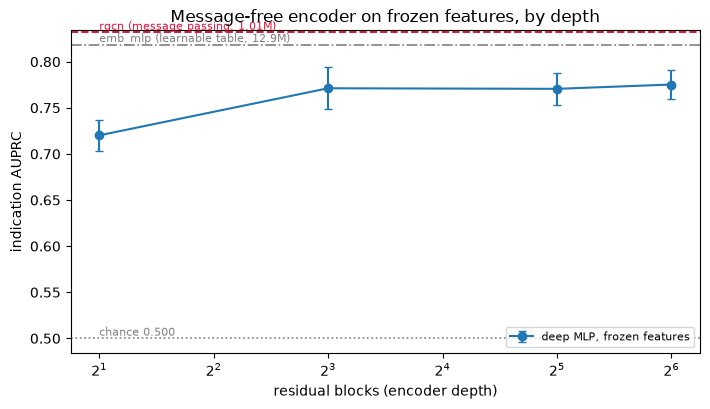

In [12]:
if summary is None:
    print('Nothing to plot yet.')
else:
    s = summary.set_index('arm')
    depth_arms = [a for a in ['deep_mlp_rz_2', 'deep_mlp_rz_8', 'deep_mlp_rz_32',
                              'deep_mlp_rz_64', 'deep_mlp_rz_100'] if a in s.index]
    if depth_arms:
        t = pd.DataFrame([{
            'arm': a,
            'depth': int(s.loc[a, 'depth']) if pd.notna(s.loc[a, 'depth']) else None,
            'encoder params': int(s.loc[a, 'encoder_params']),
            'indication': s.loc[a, 'indication'],
            'ci': s.loc[a, 'indication_ci'],
            'vs rgcn': s.loc[a, 'indication_delta'] if 'indication_delta' in s.columns else np.nan,
            'n': int(s.loc[a, 'n_seeds']),
        } for a in depth_arms]).sort_values('depth')
        display(t.style.format({'indication': '{:.4f}', 'ci': '±{:.4f}', 'vs rgcn': '{:+.4f}',
                                'encoder params': '{:,.0f}'}, na_rep='-'))

        try:
            import matplotlib.pyplot as plt
            fig, ax = plt.subplots(figsize=(7.2, 4.2))
            ax.errorbar(t.depth, t.indication, yerr=t.ci, marker='o', capsize=3,
                        label='deep MLP, frozen features')
            for y, lbl, st in [(0.5, 'chance 0.500', ':'),
                               (EMB_MLP_INDICATION, 'emb_mlp (learnable table, 12.9M)', '-.')]:
                ax.axhline(y, ls=st, lw=1.2, color='grey')
                ax.annotate(lbl, (t.depth.min(), y), fontsize=8, va='bottom', color='grey')
            if REF_ARM in s.index:
                ax.axhline(s.loc[REF_ARM, 'indication'], ls='--', lw=1.4, color='crimson')
                ax.annotate('rgcn (message passing, 1.01M)',
                            (t.depth.min(), s.loc[REF_ARM, 'indication']),
                            fontsize=8, va='bottom', color='crimson')
            ax.set_xscale('log', base=2)
            ax.set_xlabel('residual blocks (encoder depth)')
            ax.set_ylabel('indication AUPRC')
            ax.set_title('Message-free encoder on frozen features, by depth')
            ax.legend(fontsize=8, loc='lower right')
            plt.tight_layout(); plt.show()
        except Exception as e:
            print('(plot skipped: %s)' % e)
    else:
        print('No deep_mlp arms finished yet.')

### 9.2 Depth versus width versus message passing, at one parameter budget

Four arms at ~1.01M encoder parameters. The only differences are *how* the budget is spent and whether
the encoder may look at an edge.

In [13]:
MATCHED = ['rgcn', 'light_gnn_wide', 'mlp_wide', 'deep_mlp_rz_100', 'deep_mlp_rz_64']

if summary is None:
    print('Nothing to compare yet.')
else:
    s = summary.set_index('arm')
    present = [a for a in MATCHED if a in s.index]
    if present:
        t = pd.DataFrame([{
            'arm': a,
            'how the budget is spent': {
                'rgcn': 'one matrix per edge type',
                'light_gnn_wide': 'one shared matrix, widened',
                'mlp_wide': 'width, no message passing',
                'deep_mlp_rz_100': 'depth 100, no message passing',
                'deep_mlp_rz_64': 'depth 64, no message passing',
            }.get(a, '-'),
            'message passing': bool(s.loc[a, 'graph_sensitivity'] and
                                    s.loc[a, 'graph_sensitivity'] > 1e-6),
            'encoder params': int(s.loc[a, 'encoder_params']),
            'indication': s.loc[a, 'indication'],
            'contraindication': s.loc[a, 'contraindication'],
            'micro': s.loc[a, 'micro'],
            'n': int(s.loc[a, 'n_seeds']),
        } for a in present])
        display(t.style.format({'indication': '{:.4f}', 'contraindication': '{:.4f}',
                                'micro': '{:.4f}', 'encoder params': '{:,.0f}'}, na_rep='-'))

    print('\nPaired deltas, per seed:')
    CONTRASTS = [
        ('mlp_wide',       'mlp',            'width: mlp_wide - mlp (capacity at fixed depth)'),
        ('deep_mlp_rz_64',  'deep_mlp_rz_2',  'depth: 64 blocks - 2 blocks'),
        ('deep_mlp_rz_64',  'mlp_wide',       'depth 64 vs width at ~1.01M'),
        ('light_gnn_wide', 'light_gnn',      'width: light_gnn_wide - light_gnn'),
        ('light_gnn_wide', 'mlp_wide',       'message passing, isolated at ~1.01M'),
        ('deep_mlp_rz_64',  'rgcn',           'deepest message-free - published encoder'),
    ]
    rows = [r for r in (paired(a, b, lbl) for a, b, lbl in CONTRASTS) if r]
    if rows:
        display(pd.DataFrame(rows)[['contrast', 'n', 'indication', 'indication_ci',
                                    'indication_favours_a', 'contraindication',
                                    'contraindication_ci', 'micro', 'micro_ci']]
                .style.format({'indication': '{:+.4f}', 'indication_ci': '±{:.4f}',
                               'contraindication': '{:+.4f}', 'contraindication_ci': '±{:.4f}',
                               'micro': '{:+.4f}', 'micro_ci': '±{:.4f}'}, na_rep='-'))
    else:
        print('  not enough arms finished yet.')

,arm,how the budget is spent,message passing,encoder params,indication,contraindication,micro,n
0,rgcn,one matrix per edge type,True,"1,010,000",0.8318,0.7324,0.7504,20
1,light_gnn_wide,"one shared matrix, widened",True,"1,010,024",0.8058,0.7193,0.7310,20
2,mlp_wide,"width, no message passing",False,"1,010,024",0.7897,0.7036,0.7253,20
3,deep_mlp_rz_64,"depth 64, no message passing",False,"646,464",0.7752,0.6980,0.7106,20



Paired deltas, per seed:


,contrast,n,indication,indication_ci,indication_favours_a,contraindication,contraindication_ci,micro,micro_ci
0,width: mlp_wide - mlp (capacity at fixed depth),20,+0.2612,±0.0212,20,+0.0851,±0.0193,+0.1320,±0.0158
1,depth: 64 blocks - 2 blocks,20,+0.0551,±0.0141,20,+0.0262,±0.0105,+0.0301,±0.0057
2,depth 64 vs width at ~1.01M,20,-0.0145,±0.0162,6,-0.0056,±0.0124,-0.0148,±0.0073
3,width: light_gnn_wide - light_gnn,20,+0.2007,±0.0186,20,+0.0965,±0.0171,+0.1326,±0.0157
4,"message passing, isolated at ~1.01M",20,+0.0161,±0.0184,14,+0.0157,±0.0109,+0.0057,±0.0068
5,deepest message-free - published encoder,20,-0.0565,±0.0131,1,-0.0344,±0.0117,-0.0398,±0.0061


### 9.3 Save the summary

In [14]:
if summary is not None:
    out_csv = ABL_ROOT / 'deep_mlp_summary.csv'
    summary.to_csv(out_csv, index=False)
    print('wrote', out_csv.relative_to(REPO_ROOT))
    if wide is not None:
        per_seed = ABL_ROOT / 'deep_mlp_per_seed.csv'
        wide.reset_index().to_csv(per_seed, index=False)
        print('wrote', per_seed.relative_to(REPO_ROOT))

    g = long.groupby(['arm', 'seed'])
    n_imported, n_total = int(g.imported.first().sum()), int(g.ngroups)
    print('\n%d run(s) on disk: %d trained here, %d imported.'
          % (n_total, n_total - n_imported, n_imported))

    probes = long.groupby('arm').graph_sensitivity.first().dropna()
    if len(probes):
        print('\ngraph_sensitivity by arm (0 => the encoder never reads an edge):')
        for a, v in probes.items():
            print('  %-16s %.6g' % (a, v))

wrote results/ablation_deep_mlp/deep_mlp_summary.csv
wrote results/ablation_deep_mlp/deep_mlp_per_seed.csv

180 run(s) on disk: 120 trained here, 60 imported.

graph_sensitivity by arm (0 => the encoder never reads an edge):
  deep_mlp_rz_2    0
  deep_mlp_rz_32   0
  deep_mlp_rz_64   0
  deep_mlp_rz_8    0
  light_gnn        11.0909
  light_gnn_wide   107.208
  mlp              0
  mlp_wide         0
  rgcn             14.5262


---
## 10 · What this grid can and cannot support

**Can.**

- Whether `mlp`'s collapse to 0.5285 was a capacity artifact. `mlp_wide` tests that at 50× the
  parameters and fixed depth; `deep_mlp_rz_100` tests it at the R-GCN's parameter count.
- Whether per-node *free parameters* (`emb_mlp`'s table) are doing something that per-node *function
  approximation* over a frozen fingerprint cannot. Both are message-free, so message passing is held
  out of the comparison entirely.
- Message passing isolated at ~1.01M with frozen features, from `light_gnn_wide − mlp_wide`. Grid 7
  isolated it at 12.9M with learnable features (`emb_rgcn − emb_mlp` = +0.0556); this is the same
  contrast at the other end of the capacity range, and the two together say whether the value of
  message passing depends on how the node representations are parameterised.

**Cannot.**

- The residual blocks are not the same function class as the 2-layer `mlp`: they add LayerNorm, a skip
  connection and a gain, without which the stack does not train at depth. `deep_mlp_rz_2` is included
  so the depth curve is self-consistent, but `deep_mlp_rz_2` vs `mlp` is a block-design comparison,
  not a depth one.
- Equal parameter count is not equal effective capacity, and grid 10 showed the parameter-to-AUPRC
  curve is not monotonic. A deep arm that fails to beat `mlp` has not proven that no message-free
  encoder could; it has shown that this one, trained this way, does not.
- A null result could be an optimisation failure rather than a representational one. Check
  `embedding_rms` and the test BCE in §9.1a before reading anything into a flat depth curve: a
  saturated decoder reports "this arm did not train", which is a different claim entirely.
- Edge-level AUPRC only, chance 0.500. Nothing here speaks to the ranking protocol.